# LeJEPA Latent-Space Diagnostics — CIRP 2027

A **computational, reproducible and descriptive** look at what the trained LeJEPA representation of
`02_architecture_updated.ipynb` captures, and at how that representation relates to the recorded defect labels
**after** unsupervised training. It supplements the inspection-prioritisation experiment of notebook 02; it is
not a classifier and not a human-evaluation pipeline.

**What these diagnostics do not establish.** They explore learned structure and its association with labels.
They do not establish causal explanations, manufacturing root causes, defect clusters, or a reliable defect
classifier. A 2-D projection can distort the latent geometry, "nearest" means nearest under the learned
embedding only, and several defect classes have very few records.

**Inputs.** The artifacts exported by STEP 11 of notebook 02 (`notebooks/outputs/02_architecture_updated/artifacts/`):
the final models (one per seed), the pool-fitted scaler, feature order and block structure, the record
identifiers and partitions, the acquisition scores and the 300-record selections. Nothing is re-trained or
re-fitted here, except the 2-D visualisation PCA of section 4, which is fitted on the pool embeddings only.
If the artifacts are missing, run `notebooks/02_architecture_updated.ipynb` top to bottom first (about 8 minutes
on CPU).

**Outputs.** Figures, tables and a manifest in `notebooks/outputs/lejepa_latent_diagnostics/`.

| section | content |
| --- | --- |
| 0 | scope, parameters, environment |
| 1 | load and verify the trained artifacts |
| 2 | extract the representations (target, context, predicted views) |
| 3 | latent integrity checks |
| 4 | 2-D PCA projection of the latent embeddings, coloured by recorded outcome |
| 5 | defect-associated latent patterns (descriptive), nearest neighbours, production episodes |
| 6 | link to the acquisition experiment: scores and 300-record selections in latent space |
| 7 | observations and limitations |
| 8 | export manifest |

## 0. Scope, parameters and reproducibility

`PRIMARY_SEED = 0` is the first of the five predeclared seeds of notebook 02. It was not chosen by looking at
any outcome. Integrity and selection checks run on all five seeds; the figures use the primary seed only.

In [1]:
# =============================================================================
# 0. Imports, paths, parameters, environment
# =============================================================================
import ast
import json
import hashlib
import platform
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import sklearn
import torch
import torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings('ignore', message='IProgress not found')
torch.set_num_threads(8)
torch.use_deterministic_algorithms(True, warn_only=True)

def find_repo_root(start=None):
    here = Path(start or Path.cwd()).resolve()
    for cand in (here, *here.parents):
        if (cand / 'pyproject.toml').is_file() and (cand / 'data' / 'labeled_data_preprocessed.csv').is_file():
            return cand
    raise FileNotFoundError(f"Repository root not found from {here}: expected pyproject.toml and "
                            f"data/labeled_data_preprocessed.csv in this folder or a parent.")

REPO_ROOT = find_repo_root()
NB02 = REPO_ROOT / 'notebooks' / '02_architecture_updated.ipynb'
ARTIFACT_DIR = REPO_ROOT / 'notebooks' / 'outputs' / '02_architecture_updated' / 'artifacts'
RESULTS_02 = REPO_ROOT / 'notebooks' / 'outputs' / '02_architecture_updated' / 'results'
OUT_DIR = REPO_ROOT / 'notebooks' / 'outputs' / 'lejepa_latent_diagnostics'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- parameters ----------------------------------------------------
PRIMARY_SEED = 0               # first predeclared seed of notebook 02; not chosen by outcome
N_NEIGHBOURS = 5               # nearest pool neighbours per query record (section 5.2)
EPISODE_GAP_MINUTES = 30       # defects closer in time than this belong to one production episode (5.3)
SCORE_ATOL = 1e-5              # tolerance for re-computed vs exported acquisition scores
SMALL_N = 10                   # classes with fewer records are flagged as unstable

# ---------------- plotting: validated categorical slots 1-3 + neutral for pass --
CLASS_ORDER = ['pass', 'gas', 'short_shot', 'startup']
CLASS_LABEL = {'pass': 'pass', 'gas': 'gas marks', 'short_shot': 'short shot', 'startup': 'start-up'}
CLASS_COLOR = {'pass': '#a9a8a1', 'gas': '#2a78d6', 'short_shot': '#eb6834', 'startup': '#1baf7a'}
CLASS_MARKER = {'pass': '.', 'gas': 'o', 'short_shot': 'X', 'startup': '^'}
INK, MUTED = '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 9})

ENVIRONMENT = {'python': platform.python_version(), 'torch': torch.__version__, 'numpy': np.__version__,
               'pandas': pd.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__,
               'matplotlib': matplotlib.__version__, 'platform': platform.platform()}
RUN_STARTED = datetime.now().isoformat(timespec='seconds')
print(f"repo root   {REPO_ROOT}\nartifacts   {ARTIFACT_DIR}\noutputs     {OUT_DIR}")
print(f"environment {ENVIRONMENT}")

repo root   C:\Users\Iman\Desktop\CIRP Conference Study
artifacts   C:\Users\Iman\Desktop\CIRP Conference Study\notebooks\outputs\02_architecture_updated\artifacts
outputs     C:\Users\Iman\Desktop\CIRP Conference Study\notebooks\outputs\lejepa_latent_diagnostics
environment {'python': '3.13.8', 'torch': '2.14.0+cpu', 'numpy': '2.3.5', 'pandas': '3.0.5', 'scikit-learn': '1.9.0', 'scipy': '1.18.1', 'matplotlib': '3.11.1', 'platform': 'Windows-11-10.0.26300-SP0'}


## 1. Load the trained artifacts (no re-training)

Every file is checked against the SHA-256 recorded by notebook 02, the data set against its recorded hash, and
the standardised feature matrix is rebuilt from the CSV with the **exported** feature order and scaler and
compared with the hash notebook 02 recorded. The model code is not copied: the class and function definitions
are read from the STEP 2 cell of notebook 02 and executed, so this notebook uses exactly the same encoder,
predictor and mask semantics.

In [2]:
# =============================================================================
# 1.1 Required files, manifest, hashes
# =============================================================================
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

def sha256_array(a):
    return hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest()

MANIFEST_PATH = ARTIFACT_DIR / 'export_manifest.json'
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        f"{MANIFEST_PATH} not found.\nPrerequisite: run notebooks/02_architecture_updated.ipynb top to bottom "
        f"(STEP 11 writes the artifacts), e.g. from the repository root:\n"
        f"  .venv/Scripts/python.exe -m jupyter nbconvert --to notebook --execute --inplace "
        f"--ExecutePreprocessor.timeout=1800 notebooks/02_architecture_updated.ipynb")
MANIFEST = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
missing = [f for f in MANIFEST['files'] if not (ARTIFACT_DIR / f).is_file()]
if missing:
    raise FileNotFoundError(f"Artifacts listed in the manifest are missing: {missing}. Re-run notebook 02.")
changed = [f for f, h in MANIFEST['files'].items() if sha256_file(ARTIFACT_DIR / f) != h]
if changed:
    raise RuntimeError(f"Artifacts changed since notebook 02 exported them: {changed}. Re-run notebook 02.")

DATA_PATH = REPO_ROOT / MANIFEST['data_path']
if sha256_file(DATA_PATH) != MANIFEST['data_sha256']:
    raise RuntimeError(f"{DATA_PATH} differs from the data set notebook 02 was run on (SHA-256 mismatch).")

SEEDS = MANIFEST['seeds']
if PRIMARY_SEED not in SEEDS:
    raise ValueError(f"PRIMARY_SEED={PRIMARY_SEED} is not one of the exported seeds {SEEDS}")
CFG = MANIFEST['final_cfg']
CHECKPOINT = ARTIFACT_DIR / f'lejepa_final_seed{PRIMARY_SEED}.pt'
print(f"artifacts exported      {MANIFEST['created']} by {MANIFEST['producer']}")
print(f"data                    {MANIFEST['data_path']}  sha256 {MANIFEST['data_sha256'][:16]}…  ({MANIFEST['equipment']}, {MANIFEST['n_records']} records)")
print(f"configuration           '{MANIFEST['final_configuration']}': {CFG}")
print(f"seeds                   {SEEDS}  (primary {PRIMARY_SEED}; checkpoint {CHECKPOINT.relative_to(REPO_ROOT).as_posix()})")
print(f"split                   {MANIFEST['split']}")
print(f"preprocessing           {MANIFEST['preprocessing']}")
print(f"observation unit        {MANIFEST['observation_unit']}")
print(f"producer environment    {MANIFEST['environment']}")
print(f"all {len(MANIFEST['files'])} artifact hashes verified")

artifacts exported      2026-11-07T13:21:28 by notebooks/02_architecture_updated.ipynb (STEP 11)
data                    data/labeled_data_preprocessed.csv  sha256 0c54df14f020dcd4…  (S14, 5230 records)
configuration           'Baseline (frozen scoring)': {'drop_dead_sensors': True, 'latent_dim': 8, 'enc_hidden': [64, 32], 'pred_hidden': 32, 'keep_prob': 0.5, 'lam': 1.0, 'n_mask_draws': 50, 'scoring_mode': 'exact', 'lr': 0.003, 'weight_decay': 0.0001, 'batch_size': 256}
seeds                   [0, 1, 2, 3, 4]  (primary 0; checkpoint notebooks/outputs/02_architecture_updated/artifacts/lejepa_final_seed0.pt)
split                   {'method': 'GroupShuffleSplit on (EQUIP_CD, TimeStamp) groups', 'test_group_frac': 0.25, 'tuning_group_frac': 0.25, 'seed_test': 42, 'seed_tuning': 43, 'records': {'pool': 2940, 'tuning': 982, 'test': 1308}}
preprocessing           {'fitted_on': 'pool', 'scaler': 'StandardScaler', 'n_features': 24, 'dropped_sensors': ['Barrel_Temperature_7', 'Switch_Over_Posit

In [3]:
# =============================================================================
# 1.2 Model definitions, read from the STEP 2 cell of notebook 02 (not copied)
# =============================================================================
NEEDED = ['LeJEPAEncoder', 'LeJEPAPredictor', 'make_models', 'encode_full', 'all_block_masks', 'latent_uncertainty_exact']
nb02 = json.loads(NB02.read_text(encoding='utf-8'))
step2 = [c for c in nb02['cells'] if c['cell_type'] == 'code' and 'class LeJEPAEncoder' in ''.join(c['source'])]
if len(step2) != 1:
    raise RuntimeError(f"expected exactly one STEP 2 cell defining LeJEPAEncoder in {NB02.name}, found {len(step2)}")
tree = ast.parse(''.join(step2[0]['source']))
nodes = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.ClassDef)) and n.name in NEEDED]
found = [n.name for n in nodes]
if sorted(found) != sorted(NEEDED):
    raise RuntimeError(f"definitions missing from notebook 02 STEP 2: {sorted(set(NEEDED) - set(found))}")
LEJEPA = {'torch': torch, 'nn': nn, 'np': np}
exec(compile(ast.Module(body=nodes, type_ignores=[]), f'{NB02.name}:STEP2', 'exec'), LEJEPA)
LeJEPAEncoder, make_models, encode_full = LEJEPA['LeJEPAEncoder'], LEJEPA['make_models'], LEJEPA['encode_full']
all_block_masks, latent_uncertainty_exact = LEJEPA['all_block_masks'], LEJEPA['latent_uncertainty_exact']
print(f"loaded from {NB02.name} STEP 2: {found}")

loaded from 02_architecture_updated.ipynb STEP 2: ['LeJEPAEncoder', 'LeJEPAPredictor', 'make_models', 'encode_full', 'all_block_masks', 'latent_uncertainty_exact']


In [4]:
# =============================================================================
# 1.3 Data, feature order, scaler, partitions, models
# =============================================================================
records = pd.read_csv(ARTIFACT_DIR / 'records.csv', dtype={'record_id': str})
pre = np.load(ARTIFACT_DIR / 'preprocessing.npz', allow_pickle=False)
FEATURES = [str(f) for f in pre['feature_names']]
GROUP_MATRIX = torch.tensor(pre['group_matrix'])
BLOCK_OF_FEATURE = pre['block_of_feature']

df = pd.read_csv(DATA_PATH)
df = df.loc[df['EQUIP_CD'] == MANIFEST['equipment']].reset_index(drop=True)
if len(df) != len(records) or not (df['_id'].astype(str).to_numpy() == records['record_id'].to_numpy()).all():
    raise RuntimeError("the data rows do not line up with records.csv (order or identity differs)")
absent = [f for f in FEATURES if f not in df.columns]
if absent:
    raise KeyError(f"feature columns missing from the data: {absent}")
X_raw = df[FEATURES].to_numpy(dtype=np.float64)
X_scaled = (X_raw - pre['scaler_mean']) / pre['scaler_scale']
if sha256_array(X_scaled) == MANIFEST['X_scaled_sha256']:
    print("standardised features: bit-identical to notebook 02 (SHA-256 match)")
else:
    raise RuntimeError("standardised features differ from notebook 02 (feature order or scaler mismatch)")
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
N, D = X_tensor.shape

PARTITION = records['partition'].to_numpy()
pool_mask = PARTITION == 'pool'
for name, n in MANIFEST['split']['records'].items():
    if int((PARTITION == name).sum()) != n:
        raise RuntimeError(f"partition '{name}' has {(PARTITION == name).sum()} records, manifest says {n}")

MODELS = {}
for seed in SEEDS:
    ck = torch.load(ARTIFACT_DIR / f'lejepa_final_seed{seed}.pt', map_location='cpu', weights_only=True)
    if ck['feature_names'] != FEATURES or ck['input_dim'] != D:
        raise RuntimeError(f"checkpoint seed {seed}: feature order / input dimension differs from preprocessing.npz")
    enc, pred = make_models(D, ck['config']['latent_dim'], tuple(ck['config']['enc_hidden']), ck['config']['pred_hidden'])
    enc.load_state_dict(ck['encoder_state_dict'], strict=True)
    pred.load_state_dict(ck['predictor_state_dict'], strict=True)
    MODELS[seed] = (enc.eval(), pred.eval())
LATENT_DIM = CFG['latent_dim']
print(f"{N} records x {D} sensors; {GROUP_MATRIX.shape[0]} correlated blocks; partitions "
      f"{ {k: int((PARTITION == k).sum()) for k in ('pool', 'tuning', 'test')} }")
print(f"loaded {len(MODELS)} checkpoints (strict state-dict match); latent_dim = {LATENT_DIM}")

standardised features: bit-identical to notebook 02 (SHA-256 match)
5230 records x 24 sensors; 6 correlated blocks; partitions {'pool': 2940, 'tuning': 982, 'test': 1308}
loaded 5 checkpoints (strict state-dict match); latent_dim = 8


## 2. Extract and document the representations

Three different latent objects exist in LeJEPA; they are kept apart here.

| representation | definition | mask | role here |
| --- | --- | --- | --- |
| **full target view** `z_target` | `encoder(x, mask = all ones)` | none: deterministic | **primary embedding** for every plot and table |
| masked context view `z_context(m)` | `encoder(x * m, m)` | one of the admissible block masks `m` | only to recompute the acquisition score |
| predicted target `z_pred(m)` | `predictor(z_context(m))` | same `m` | only to recompute the acquisition score |

The acquisition score of notebook 02 (exact mode) is the mean over **all** admissible block masks (every keep
pattern of the correlated blocks except "all hidden" and "all visible") of `‖z_target − z_pred(m)‖₂`. Because
all masks are enumerated, no mask sampling and no mask seed is involved. `z_target` is chosen as the primary
embedding because it is mask-free and is the object the predictor is trained to match.

In [5]:
# =============================================================================
# 2.1 Representations of the primary seed, and the score recomputed from them
# =============================================================================
enc, pred = MODELS[PRIMARY_SEED]
keep_patterns, masks = all_block_masks(GROUP_MATRIX)
with torch.no_grad():
    z_target = encode_full(enc, X_tensor)                                          # (N, latent)
    z_context = torch.stack([enc(X_tensor, m.expand_as(X_tensor)) for m in masks])  # (masks, N, latent)
    z_pred = pred(z_context.reshape(-1, LATENT_DIM)).reshape(z_context.shape)       # (masks, N, latent)
    score_from_views = torch.norm(z_target.unsqueeze(0) - z_pred, dim=2).mean(dim=0).numpy()
score_02_fn = latent_uncertainty_exact(enc, pred, X_tensor, GROUP_MATRIX)
max_diff = float(np.abs(score_from_views - score_02_fn).max())
assert max_diff < SCORE_ATOL, f"score from the views differs from notebook 02's function by {max_diff}"
Z = z_target.numpy().astype(np.float64)

REPRESENTATIONS = pd.DataFrame([
    ('z_target (primary)', tuple(z_target.shape), 'none (all sensors visible)', 'plots, tables, neighbours'),
    ('z_context', tuple(z_context.shape), f'all {len(masks)} admissible block masks', 'score recomputation only'),
    ('z_pred', tuple(z_pred.shape), f'all {len(masks)} admissible block masks', 'score recomputation only'),
], columns=['representation', 'shape', 'mask policy', 'used for'])
print(REPRESENTATIONS.to_string(index=False))
print(f"\nexact score recomputed from z_target / z_pred matches notebook 02's latent_uncertainty_exact: max |diff| = {max_diff:.2e}")

emb = records.copy()
emb['TimeStamp'] = pd.to_datetime(emb['TimeStamp'])
for j in range(LATENT_DIM):
    emb[f'z{j}'] = Z[:, j]
emb['lejepa_exact_score'] = score_02_fn.astype(np.float64)
ZCOLS = [f'z{j}' for j in range(LATENT_DIM)]
np.savez(OUT_DIR / f'latent_z_target_seed{PRIMARY_SEED}.npz', record_id=emb['record_id'].to_numpy(), z_target=Z,
         partition=PARTITION)

    representation         shape                   mask policy                  used for
z_target (primary)     (5230, 8)    none (all sensors visible) plots, tables, neighbours
         z_context (62, 5230, 8) all 62 admissible block masks  score recomputation only
            z_pred (62, 5230, 8) all 62 admissible block masks  score recomputation only

exact score recomputed from z_target / z_pred matches notebook 02's latent_uncertainty_exact: max |diff| = 0.00e+00


## 3. Latent integrity checks

Each check fails visibly. "Label isolation" means: no label or metadata column is a model input, the
checkpoints take exactly the exported sensors, the labels file is read only in section 4 (after the
representations and scores exist), and the exported 300-record selections are reproduced from the label-free
scores alone.

In [6]:
# =============================================================================
# 3.1 Shape, finiteness, variance, rank, identity, alignment, label isolation
# =============================================================================
CHECKS = []
def check(name, ok, value):
    CHECKS.append({'check': name, 'status': 'PASS' if ok else 'FAIL', 'value': value})

def effective_rank(z):
    eig = np.linalg.svd(np.cov(np.asarray(z).T), compute_uv=False)
    p = eig / eig.sum()
    return float(np.exp(-(p * np.log(p + 1e-12)).sum()))

check('embedding shape = (records, latent_dim)', Z.shape == (N, LATENT_DIM), str(Z.shape))
check('all embedding values finite', bool(np.isfinite(Z).all()), int((~np.isfinite(Z)).sum()))
dim_std = Z[pool_mask].std(axis=0)
check('no degenerate latent dimension (pool std > 1e-6)', bool((dim_std > 1e-6).all()), np.round(dim_std, 4).tolist())
er_pool = effective_rank(Z[pool_mask])
check('pool effective rank (of latent_dim)', er_pool > 1.0, f"{er_pool:.3f} / {LATENT_DIM}")
check('record_id unique', bool(emb['record_id'].is_unique), int(emb['record_id'].duplicated().sum()))
check('no missing records (rows = manifest)', N == MANIFEST['n_records'], N)

# the embedding belongs to the intended checkpoint: its latent statistics equal notebook 02's per-seed results
res02 = pd.read_csv(RESULTS_02 / 'experiment_results_per_seed.csv')
for seed, (e_, p_) in MODELS.items():
    with torch.no_grad():
        zp = encode_full(e_, X_tensor[pool_mask]).numpy()
    row = res02[(res02.Configuration == MANIFEST['final_configuration']) & (res02.Seed == seed)].iloc[0]
    ok = np.isclose(effective_rank(zp), row['Effective rank'], atol=1e-6) and np.isclose(float(zp.var(axis=0).mean()), row['Latent variance'], atol=1e-6)
    check(f'seed {seed}: pool effective rank and latent variance equal notebook 02', bool(ok),
          f"{effective_rank(zp):.4f} / {float(zp.var(axis=0).mean()):.4f}")

# the two part records of one shot are identical sensor rows, hence identical embeddings
pairs = emb.groupby('group_id').filter(lambda g: len(g) == 2).sort_values(['group_id', 's14_row'])
zp2 = pairs[ZCOLS].to_numpy().reshape(-1, 2, LATENT_DIM)
twin_diff = float(np.abs(zp2[:, 0] - zp2[:, 1]).max())
check('paired part records (same shot) have identical embeddings', twin_diff < 1e-5, f"{len(zp2)} pairs, max |diff| {twin_diff:.1e}")

# label isolation
LABEL_LIKE = {'PassOrFail', 'Reason', 'defect_type', '_id', 'TimeStamp', 'PART_NAME', 'EQUIP_CD', 'EQUIP_NAME',
              'PART_FACT_PLAN_DATE', 'PART_FACT_SERIAL'}
check('no label / metadata column among model inputs', not (set(FEATURES) & LABEL_LIKE), f"{D} sensors")
check('encoder input width = 2 x sensors (values + mask channel)',
      enc.net[0].in_features == 2 * D, enc.net[0].in_features)
check('labels not loaded before section 4', 'labels' not in globals(), 'by construction')

# exported selections are reproduced from the label-free scores (all seeds)
acq = pd.read_csv(ARTIFACT_DIR / 'pool_acquisition.csv', dtype={'record_id': str})
pool_rows = np.where(pool_mask)[0]
for seed, (e_, p_) in MODELS.items():
    a = acq[acq.seed == seed]
    sc = latent_uncertainty_exact(e_, p_, X_tensor[pool_rows], GROUP_MATRIX)
    same_ids = (a['record_id'].to_numpy() == emb['record_id'].to_numpy()[pool_rows]).all()
    score_ok = np.abs(a['lejepa_score'].to_numpy() - sc).max() < SCORE_ATOL
    order = np.lexsort((pool_rows, -sc))                      # notebook 02 top_k tie-break: score, then row
    top = np.zeros(len(pool_rows), bool); top[order[:MANIFEST['budget']]] = True
    check(f'seed {seed}: pool ids aligned, scores and top-{MANIFEST["budget"]} selection reproduced',
          bool(same_ids and score_ok and (top == a['lejepa_selected'].to_numpy()).all()),
          f"{int(a['lejepa_selected'].sum())} selected")

INTEGRITY = pd.DataFrame(CHECKS)
INTEGRITY.to_csv(OUT_DIR / 'latent_integrity_checks.csv', index=False)
with pd.option_context('display.max_colwidth', 90, 'display.width', 200):
    print(INTEGRITY.to_string(index=False))
assert (INTEGRITY.status == 'PASS').all(), "integrity check failed: see the table above"
print(f"\nall {len(INTEGRITY)} integrity checks PASS")

                                                            check status                                                            value
                          embedding shape = (records, latent_dim)   PASS                                                        (5230, 8)
                                      all embedding values finite   PASS                                                                0
                 no degenerate latent dimension (pool std > 1e-6)   PASS [0.1772, 0.6203, 0.7539, 0.8037, 0.6304, 0.7485, 0.5206, 0.5357]
                              pool effective rank (of latent_dim)   PASS                                                        2.043 / 8
                                                 record_id unique   PASS                                                                0
                             no missing records (rows = manifest)   PASS                                                             5230
seed 0: pool effective rank and la

## 4. Two-dimensional projection of the latent embeddings

**Labels enter here**, joined by `record_id`, for retrospective description only.

The projection is a 2-component PCA of `z_target`, **fitted on the pool embeddings only** and applied unchanged
to the tuning and test records. This visualisation PCA is unrelated to the PCA reconstruction-error acquisition
baseline of notebook 02. UMAP is not installed in the project environment and was not added; t-SNE was not
used. Apparent separation or clustering in two dimensions is not evidence of separability in the latent space.

In [7]:
# =============================================================================
# 4.1 Join the labels (retrospective analysis only) and count the classes
# =============================================================================
labels = pd.read_csv(ARTIFACT_DIR / 'evaluation_labels.csv', dtype={'record_id': str})
if not labels['record_id'].is_unique or set(labels['record_id']) != set(emb['record_id']):
    raise RuntimeError("evaluation_labels.csv does not cover exactly the exported records")
emb = emb.merge(labels[['record_id', 'PassOrFail', 'defect_type']], on='record_id', how='left', validate='one_to_one')
assert emb['defect_type'].notna().all() and set(emb['defect_type']) <= set(CLASS_ORDER)
emb['cls'] = pd.Categorical(emb['defect_type'], categories=CLASS_ORDER, ordered=True)

part_order = ['pool', 'tuning', 'test']
COUNTS = pd.crosstab(emb['partition'], emb['cls']).reindex(index=part_order, columns=CLASS_ORDER, fill_value=0)
COUNTS['records'] = COUNTS.sum(axis=1)
COUNTS['defect share %'] = (100 * (COUNTS['records'] - COUNTS['pass']) / COUNTS['records']).round(2)
COUNTS['groups (shots)'] = emb.groupby('partition')['group_id'].nunique().reindex(part_order)
COUNTS.loc['all'] = COUNTS.loc[part_order].sum()
COUNTS.loc['all', 'defect share %'] = round(100 * (COUNTS.loc['all', 'records'] - COUNTS.loc['all', 'pass']) / COUNTS.loc['all', 'records'], 2)
COUNTS = COUNTS.astype({c: int for c in CLASS_ORDER + ['records', 'groups (shots)']})
COUNTS.to_csv(OUT_DIR / 'class_counts_by_partition.csv')
print("part records per partition and recorded outcome:")
print(COUNTS.to_string())
small = [(p, c) for p in part_order for c in CLASS_ORDER[1:] if COUNTS.loc[p, c] < SMALL_N]
print(f"\nSevere imbalance: defects are {COUNTS.loc['all', 'defect share %']}% of records. "
      f"{len(small)} of {3 * len(part_order)} partition x defect-type cells hold fewer than {SMALL_N} records; "
      f"per-type statements below are unstable.")

part records per partition and recorded outcome:
cls        pass  gas  short_shot  startup  records  defect share %  groups (shots)
partition                                                                         
pool       2908   18          10        4     2940            1.09            1476
tuning      969    9           2        2      982            1.32             492
test       1293    8           3        4     1308            1.15             656
all        5170   35          15       10     5230            1.15            2624

Severe imbalance: defects are 1.15% of records. 7 of 9 partition x defect-type cells hold fewer than 10 records; per-type statements below are unstable.


visualisation PCA (fit on 2940 pool embeddings): PC1 54.4%, PC2 45.3% of pool latent variance (cumulative 99.6%; all components: [54.4, 45.3, 0.2, 0.1, 0.0, 0.0, 0.0, 0.0])


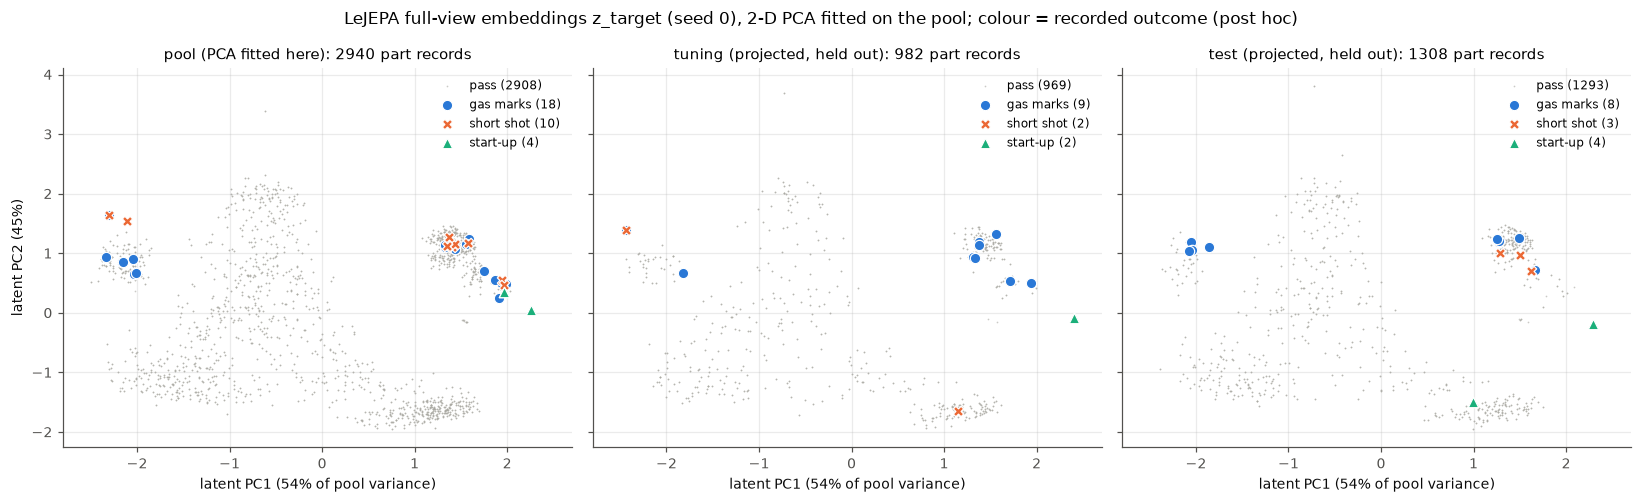

In [8]:
# =============================================================================
# 4.2 PCA of z_target fitted on the pool, applied to all partitions
# =============================================================================
vis_pca = PCA(n_components=2, svd_solver='full').fit(Z[pool_mask])
P = vis_pca.transform(Z)
emb['lat_pc1'], emb['lat_pc2'] = P[:, 0], P[:, 1]
full_pca = PCA(svd_solver='full').fit(Z[pool_mask])
evr = full_pca.explained_variance_ratio_
print(f"visualisation PCA (fit on {pool_mask.sum()} pool embeddings): PC1 {evr[0]*100:.1f}%, PC2 {evr[1]*100:.1f}% "
      f"of pool latent variance (cumulative {evr[:2].sum()*100:.1f}%; all components: {np.round(evr*100, 1).tolist()})")

def scatter_classes(ax, d, legend=False, pass_size=5):
    for c in CLASS_ORDER:
        s = d[d['cls'] == c]
        if c == 'pass':
            ax.scatter(s.lat_pc1, s.lat_pc2, s=pass_size, c=CLASS_COLOR[c], marker='.', linewidths=0, alpha=0.6,
                       label=f"{CLASS_LABEL[c]} ({len(s)})", zorder=1)
        else:
            ax.scatter(s.lat_pc1, s.lat_pc2, s=46, c=CLASS_COLOR[c], marker=CLASS_MARKER[c], edgecolors='white',
                       linewidths=0.8, label=f"{CLASS_LABEL[c]} ({len(s)})", zorder=3)
    if legend:
        ax.legend(loc='best', frameon=False, fontsize=8, markerscale=1.0)

xl = (P[:, 0].min() - 0.3, P[:, 0].max() + 0.3); yl = (P[:, 1].min() - 0.3, P[:, 1].max() + 0.3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, p in zip(axes, part_order):
    d = emb[emb.partition == p]
    scatter_classes(ax, d, legend=True)
    ax.set_title(f"{p}{' (PCA fitted here)' if p == 'pool' else ' (projected, held out)'}: {len(d)} part records", fontsize=10)
    ax.set_xlabel(f'latent PC1 ({evr[0]*100:.0f}% of pool variance)')
    ax.set_xlim(xl); ax.set_ylim(yl)
axes[0].set_ylabel(f'latent PC2 ({evr[1]*100:.0f}%)')
fig.suptitle(f'LeJEPA full-view embeddings z_target (seed {PRIMARY_SEED}), 2-D PCA fitted on the pool; colour = recorded outcome (post hoc)', fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / 'latent_pca_by_partition.png', bbox_inches='tight'); plt.show()
emb[['record_id', 'partition', 'group_id', 'defect_type', 'lat_pc1', 'lat_pc2']].to_csv(OUT_DIR / 'latent_pca_coordinates.csv', index=False)

## 5. Defect-associated latent patterns (descriptive only)

Three plain summaries, each computed per partition:

1. **Distributions** of the two visualisation coordinates by recorded outcome (median and inter-quartile range).
2. **Nearest pool neighbours** of every record under the Euclidean distance between `z_target` vectors. The
   query's own shot (its paired part record, which has the same embedding) is excluded. "Nearest" means nearest
   under this learned embedding, not similar in mechanism. The time gap to the neighbours is reported because
   records produced close together in time may be close in latent space for that reason alone.
3. **Production episodes**: defects closer in time than `EPISODE_GAP_MINUTES` are grouped into one episode, to
   show how much of each defect type is a single burst.

partition      class    n              note  lat_pc1 median   lat_pc1 IQR  lat_pc2 median    lat_pc2 IQR
     pool       pass 2908                            -0.176 [-1.06, 1.32]           0.245  [-1.22, 1.05]
     pool        gas   18                             1.371 [-2.04, 1.71]           0.880   [0.65, 1.12]
     pool short_shot   10                             1.385 [-1.25, 1.54]           1.162   [1.11, 1.48]
     pool    startup    4 unstable (n < 10)           2.115  [1.97, 2.26]           0.204   [0.05, 0.36]
   tuning       pass  969                            -0.049 [-1.17, 1.33]          -0.175  [-1.31, 0.98]
   tuning        gas    9 unstable (n < 10)           1.373  [1.32, 1.56]           0.942   [0.68, 1.20]
   tuning short_shot    2 unstable (n < 10)          -0.645 [-1.54, 0.25]          -0.129  [-0.89, 0.63]
   tuning    startup    2 unstable (n < 10)           2.405  [2.40, 2.40]          -0.087 [-0.09, -0.09]
     test       pass 1293                            -0

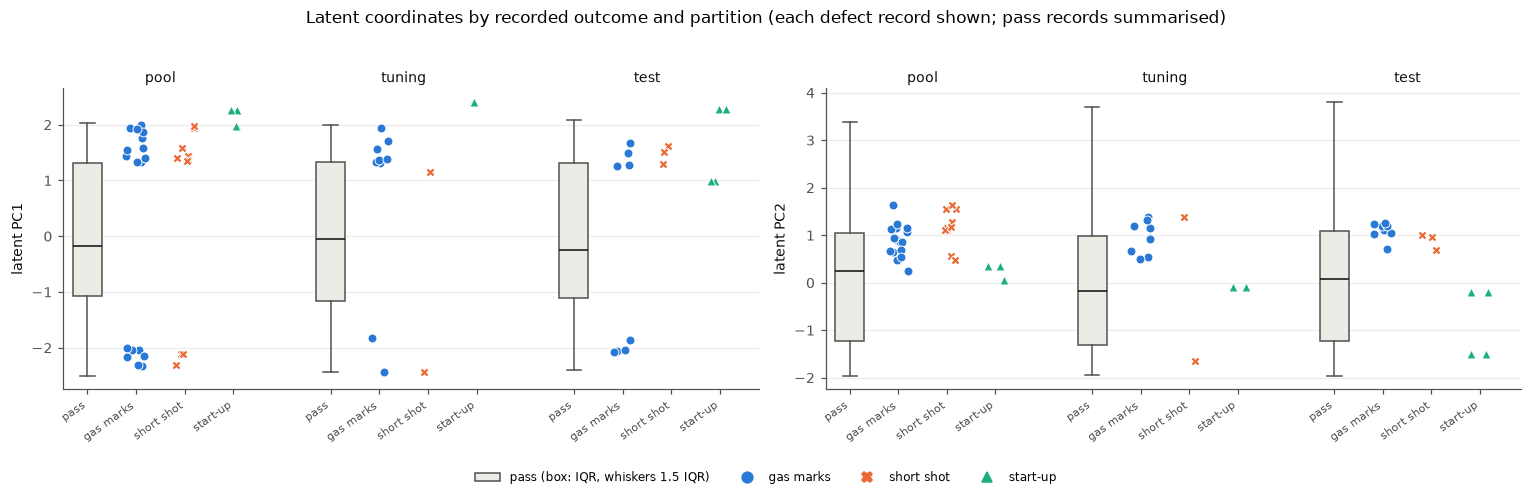

In [9]:
# =============================================================================
# 5.1 Distribution of the latent coordinates by recorded outcome
# =============================================================================
rows = []
for p in part_order:
    for c in CLASS_ORDER:
        s = emb[(emb.partition == p) & (emb.cls == c)]
        r = {'partition': p, 'class': c, 'n': len(s), 'note': 'unstable (n < %d)' % SMALL_N if len(s) < SMALL_N else ''}
        for col in ('lat_pc1', 'lat_pc2'):
            q = s[col].quantile([0.25, 0.5, 0.75]) if len(s) else pd.Series([np.nan] * 3, index=[0.25, 0.5, 0.75])
            r[f'{col} median'], r[f'{col} IQR'] = round(q[0.5], 3), f"[{q[0.25]:.2f}, {q[0.75]:.2f}]"
        rows.append(r)
PC_SUMMARY = pd.DataFrame(rows)
PC_SUMMARY.to_csv(OUT_DIR / 'latent_pc_summary_by_class.csv', index=False)
with pd.option_context('display.width', 200):
    print(PC_SUMMARY.to_string(index=False))

rng_jit = np.random.default_rng(0)                     # jitter only, for display
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, col in zip(axes, ('lat_pc1', 'lat_pc2')):
    for k, p in enumerate(part_order):
        for i, c in enumerate(CLASS_ORDER):
            s = emb[(emb.partition == p) & (emb.cls == c)][col]
            x0 = k * (len(CLASS_ORDER) + 1) + i
            if c == 'pass':
                ax.boxplot([s], positions=[x0], widths=0.6, showfliers=False, patch_artist=True,
                           boxprops=dict(facecolor='#ecebe6', edgecolor=MUTED), medianprops=dict(color=INK),
                           whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
            else:
                ax.scatter(x0 + rng_jit.uniform(-0.2, 0.2, len(s)), s, s=34, c=CLASS_COLOR[c], marker=CLASS_MARKER[c],
                           edgecolors='white', linewidths=0.6, zorder=3)
    ticks = [k * (len(CLASS_ORDER) + 1) + i for k in range(3) for i in range(len(CLASS_ORDER))]
    ax.set_xticks(ticks)
    ax.set_xticklabels([CLASS_LABEL[c] for p in part_order for c in CLASS_ORDER], fontsize=7, rotation=35, ha='right')
    for k, p in enumerate(part_order):
        ax.text(k * (len(CLASS_ORDER) + 1) + (len(CLASS_ORDER) - 1) / 2, 1.01, p, transform=ax.get_xaxis_transform(),
                ha='center', va='bottom', fontsize=9, color=INK)
    ax.set_ylabel(f'latent {col[4:].upper()}'); ax.grid(axis='x', visible=False)
handles = [Line2D([], [], marker=CLASS_MARKER[c], ls='', color=CLASS_COLOR[c], markersize=7, label=CLASS_LABEL[c]) for c in CLASS_ORDER[1:]]
handles = [plt.Rectangle((0, 0), 1, 1, fc='#ecebe6', ec=MUTED, label='pass (box: IQR, whiskers 1.5 IQR)')] + handles
fig.legend(handles=handles, frameon=False, fontsize=8, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Latent coordinates by recorded outcome and partition (each defect record shown; pass records summarised)', fontsize=11, y=1.03)
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(OUT_DIR / 'latent_pc_distributions_by_class.png', bbox_inches='tight'); plt.show()

In [10]:
# =============================================================================
# 5.2 Nearest pool neighbours in z_target (own shot excluded)
# =============================================================================
pool_idx = np.where(pool_mask)[0]
ref_Z, ref_group = Z[pool_idx], emb['group_id'].to_numpy()[pool_idx]
nn_index = NearestNeighbors(n_neighbors=N_NEIGHBOURS + 2).fit(ref_Z)      # +2: a shot has at most two records
dist, ind = nn_index.kneighbors(Z)
grp = emb['group_id'].to_numpy(); ts = emb['TimeStamp'].to_numpy(); cls = emb['defect_type'].to_numpy()
ids = emb['record_id'].to_numpy(); yv = emb['PassOrFail'].to_numpy()

nn_rows = []
for i in range(N):
    keep = [(d, pool_idx[j]) for d, j in zip(dist[i], ind[i]) if ref_group[j] != grp[i]][:N_NEIGHBOURS]
    assert len(keep) == N_NEIGHBOURS
    nb = np.array([j for _, j in keep])
    gaps_h = np.abs((ts[nb] - ts[i]) / np.timedelta64(1, 'h')).astype(float)
    nn_rows.append({'record_id': ids[i], 'partition': PARTITION[i], 'class': cls[i], 'is_defect': int(yv[i]),
                    'share_defect_neighbours': float(yv[nb].mean()),
                    'share_same_type_neighbours': float((cls[nb] == cls[i]).mean()) if yv[i] else np.nan,
                    'distinct_neighbour_shots': int(len(np.unique(grp[nb]))),
                    'median_time_gap_h': float(np.median(gaps_h)), 'mean_distance': float(np.mean([d for d, _ in keep])),
                    'neighbour_ids': ';'.join(ids[nb]), 'neighbour_classes': ';'.join(cls[nb]),
                    'neighbour_time_gaps_h': ';'.join(f'{g:.2f}' for g in gaps_h)})
NN = pd.DataFrame(nn_rows)
pool_rate = float(yv[pool_mask].mean())
NN_SUMMARY = (NN.groupby(['partition', 'class'], sort=False)
                .agg(n=('record_id', 'size'), share_defect_neighbours=('share_defect_neighbours', 'mean'),
                     share_same_type_neighbours=('share_same_type_neighbours', 'mean'),
                     median_time_gap_h=('median_time_gap_h', 'median'))
                .reindex([(p, c) for p in part_order for c in CLASS_ORDER]).dropna(how='all').round(3))
NN_SUMMARY['note'] = np.where(NN_SUMMARY['n'] < SMALL_N, f'unstable (n < {SMALL_N})', '')
NN[NN.is_defect == 1].drop(columns=['is_defect']).to_csv(OUT_DIR / 'nearest_neighbours_of_defects.csv', index=False)
NN_SUMMARY.to_csv(OUT_DIR / 'nearest_neighbour_summary.csv')
print(f"{N_NEIGHBOURS} nearest POOL neighbours per record (own shot excluded); pool defect base rate {pool_rate:.4f}")
print("share_defect_neighbours: mean share of defective part records among the neighbours (compare with the base rate)")
print("median_time_gap_h: median over query records of their median |time gap| to the neighbours, in hours\n")
with pd.option_context('display.width', 200):
    print(NN_SUMMARY.to_string())

5 nearest POOL neighbours per record (own shot excluded); pool defect base rate 0.0109
share_defect_neighbours: mean share of defective part records among the neighbours (compare with the base rate)
median_time_gap_h: median over query records of their median |time gap| to the neighbours, in hours

                         n  share_defect_neighbours  share_same_type_neighbours  median_time_gap_h               note
partition class                                                                                                      
pool      pass        2908                    0.009                         NaN              0.800                   
          gas           18                    0.111                       0.033              0.669                   
          short_shot    10                    0.180                       0.080              0.716                   
          startup        4                    0.200                       0.200            196.060  unstable (

In [11]:
# =============================================================================
# 5.3 Production episodes of the recorded defects (shared bursts, possible confounding)
# =============================================================================
dfx = emb[emb.PassOrFail == 1].sort_values(['TimeStamp', 's14_row']).copy()
new_ep = dfx['TimeStamp'].diff().gt(pd.Timedelta(minutes=EPISODE_GAP_MINUTES))
dfx['episode'] = new_ep.cumsum().astype(int) + 1
EPISODES = (dfx.groupby('episode')
               .agg(start=('TimeStamp', 'min'), end=('TimeStamp', 'max'), defect_records=('record_id', 'size'),
                    shots=('group_id', 'nunique'),
                    types=('defect_type', lambda s: ', '.join(f'{k} {v}' for k, v in s.value_counts().items())),
                    partitions=('partition', lambda s: ', '.join(f'{k} {v}' for k, v in s.value_counts().items())),
                    parts=('PART_NAME', lambda s: ', '.join(sorted(set(s))))))
EPISODES.to_csv(OUT_DIR / 'defect_episodes.csv')
by_type = (dfx.groupby('defect_type').agg(records=('record_id', 'size'), shots=('group_id', 'nunique'),
                                          episodes=('episode', 'nunique'),
                                          partitions_spanned=('partition', lambda s: ', '.join(sorted(set(s)))))
              .reindex(CLASS_ORDER[1:]))
print(f"{len(dfx)} defective part records in {dfx['group_id'].nunique()} shots and {len(EPISODES)} episodes "
      f"(gap rule: > {EPISODE_GAP_MINUTES} min starts a new episode)\n")
print(by_type.to_string())
print("\nepisodes with at least 3 defective records:")
with pd.option_context('display.width', 250, 'display.max_colwidth', 80):
    print(EPISODES[EPISODES.defect_records >= 3].to_string())
su = dfx[dfx.defect_type == 'startup']
su_eps = su.groupby('episode')['partition'].agg(lambda s: sorted(set(s)))
print(f"\nstart-up defects: {len(su)} records in {su['episode'].nunique()} episode(s); partitions per episode: {su_eps.to_dict()}")
if any(len(v) > 1 for v in su_eps.values):
    print("-> at least one start-up episode is split across partitions: records of one burst appear in both the pool "
          "and a held-out partition, so held-out start-up results are not independent of the pool.")

60 defective part records in 52 shots and 15 episodes (gap rule: > 30 min starts a new episode)

             records  shots  episodes  partitions_spanned
defect_type                                              
gas               35     35        12  pool, test, tuning
short_shot        15     14         9  pool, test, tuning
startup           10      5         1  pool, test, tuning

episodes with at least 3 defective records:
                      start                 end  defect_records  shots                 types                 partitions                                         parts
episode                                                                                                                                                              
1       2020-10-16 05:21:38 2020-10-16 05:57:20              17     14  gas 13, short_shot 4  pool 10, test 4, tuning 3  CN7 W/S SIDE MLD'G LH, CN7 W/S SIDE MLD'G RH
2       2020-10-22 00:51:52 2020-10-22 01:26:54               4      4

## 6. Link to the acquisition experiment

The exported LeJEPA scores and 300-record selections are joined by `record_id`. Section 3 has already verified
that they are reproduced from the label-free scores. Below, the defect counts of the selections are compared
with the discovery table that notebook 02 reported (`final_discovery_per_seed.csv`), and the selections are
shown in the latent projection. The PCA reconstruction-error selection of notebook 02 is shown for comparison.
It is an acquisition baseline, different from the visualisation PCA. No threshold, hyper-parameter or selection
is tuned here, and held-out labels are not used for anything but description.

In [12]:
# =============================================================================
# 6.1 Join scores and selections; verify population, budget and reported counts
# =============================================================================
BUDGET = MANIFEST['budget']
disc02 = pd.read_csv(RESULTS_02 / 'final_discovery_per_seed.csv')
LEJ = 'LeJEPA latent prediction error (exact)'
PCA_NAME = f"PCA({MANIFEST['preprocessing']['pca_baseline_k']}) reconstruction error"
method_flag = {LEJ: 'lejepa_selected', PCA_NAME: 'pca_selected', 'Random sampling': 'random_selected'}
pool_lab = emb.loc[pool_mask, ['record_id', 'group_id', 'PassOrFail', 'defect_type']]
sel_rows = []
for seed in SEEDS:
    a = acq[acq.seed == seed].merge(pool_lab, on='record_id', how='left', validate='one_to_one')
    assert len(a) == pool_mask.sum() and a['PassOrFail'].notna().all(), "pool population differs"
    for method, flag in method_flag.items():
        s = a[a[flag]]
        assert len(s) == BUDGET, f"{method} seed {seed}: {len(s)} selected, budget {BUDGET}"
        reported = disc02[(disc02.Method == method) & (disc02.Seed == seed)].iloc[0]
        found = int(s.PassOrFail.sum())
        sel_rows.append({'seed': seed, 'method': method, 'selected': len(s), 'distinct shots': s.group_id.nunique(),
                         'defects found': found, 'reported by 02': int(reported['Defects found']),
                         'match': found == int(reported['Defects found']),
                         'defective shots': s.loc[s.PassOrFail == 1, 'group_id'].nunique()})
    j = (a.lejepa_selected & a.pca_selected).sum() / (a.lejepa_selected | a.pca_selected).sum()
    sel_rows[-3]['Jaccard with PCA selection'] = round(float(j), 3)
SELECTION = pd.DataFrame(sel_rows)
SELECTION.to_csv(OUT_DIR / 'selection_check_by_seed.csv', index=False)
assert SELECTION['match'].all(), "defect counts from the exported selections differ from notebook 02's table"
with pd.option_context('display.width', 200):
    print(SELECTION.to_string(index=False))
print(f"\nall {len(SELECTION)} (seed, method) defect counts equal the counts reported by notebook 02")
print("\nnotebook 02 discovery summary (context, not recomputed):")
with pd.option_context('display.width', 250, 'display.max_columns', 20):
    print(pd.read_csv(RESULTS_02 / 'final_discovery_summary.csv', index_col=0).to_string())

 seed                                 method  selected  distinct shots  defects found  reported by 02  match  defective shots  Jaccard with PCA selection
    0 LeJEPA latent prediction error (exact)       300             155             15              15   True               11                       0.154
    0            PCA(3) reconstruction error       300             151             11              11   True                9                         NaN
    0                        Random sampling       300             283              3               3   True                3                         NaN
    1 LeJEPA latent prediction error (exact)       300             150             12              12   True                9                       0.163
    1            PCA(3) reconstruction error       300             151             11              11   True                9                         NaN
    1                        Random sampling       300             286      

pool part records by LeJEPA selection and recorded outcome (seed 0):
defect_type         pass  gas  short_shot  startup  total
lejepa_selected                                          
not selected        2623   12           5        0   2640
selected (top-300)   285    6           5        4    300
total               2908   18          10        4   2940

Euclidean distance of z_target to the pool mean embedding, median [IQR]:
  not selected 1.850 [1.494, 2.041]  (n=2640)
  selected     1.586 [1.184, 2.045]  (n=300)
Spearman(LeJEPA exact score, distance to pool mean) on the pool = -0.127


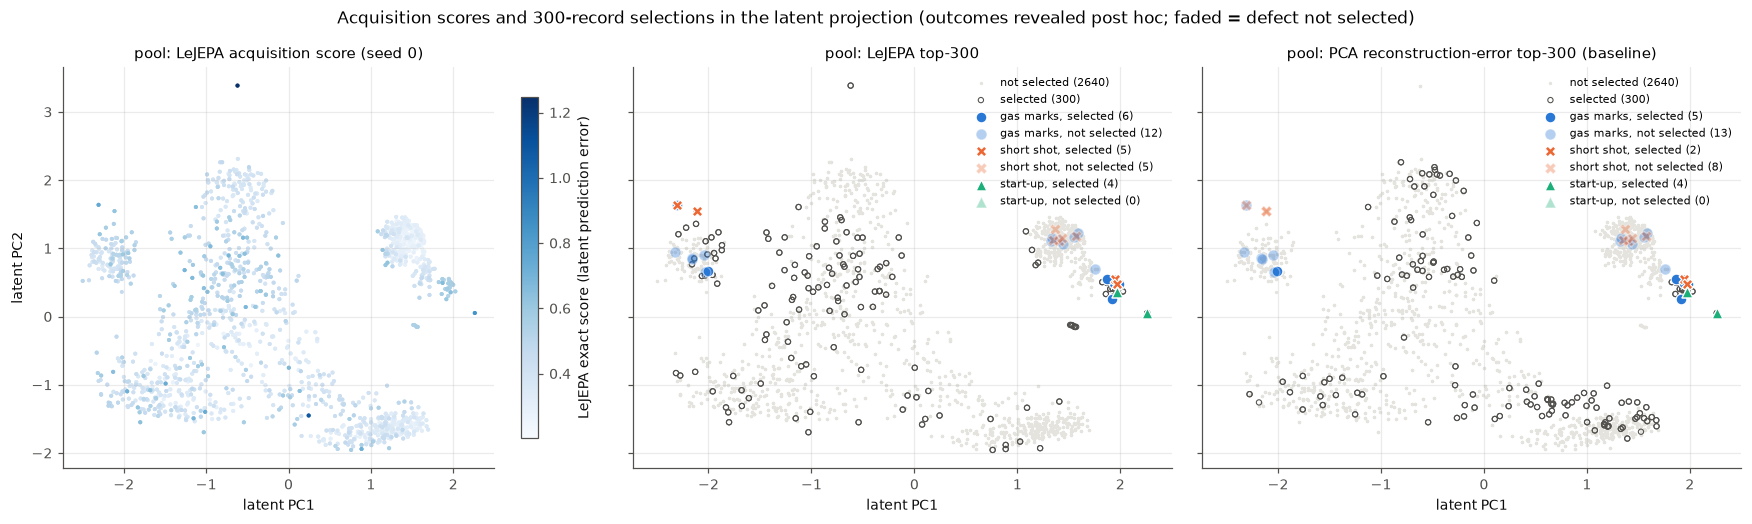

In [13]:
# =============================================================================
# 6.2 Selected vs not selected, primary seed: outcome breakdown and position in latent space
# =============================================================================
a0 = acq[acq.seed == PRIMARY_SEED][['record_id', 'lejepa_selected', 'pca_selected', 'random_selected']]
pe = emb[pool_mask].merge(a0, on='record_id', how='left', validate='one_to_one')
SEL_X_CLASS = pd.crosstab(pe['lejepa_selected'].map({True: 'selected (top-300)', False: 'not selected'}), pe['defect_type'].astype(str),
                          margins=True, margins_name='total').reindex(columns=CLASS_ORDER + ['total'])
SEL_X_CLASS.to_csv(OUT_DIR / f'selection_by_outcome_seed{PRIMARY_SEED}.csv')
print(f"pool part records by LeJEPA selection and recorded outcome (seed {PRIMARY_SEED}):")
print(SEL_X_CLASS.to_string())
centre = Z[pool_mask].mean(axis=0)
pe['dist_to_pool_mean'] = np.linalg.norm(pe[ZCOLS].to_numpy() - centre, axis=1)
print("\nEuclidean distance of z_target to the pool mean embedding, median [IQR]:")
for k, s in pe.groupby('lejepa_selected')['dist_to_pool_mean']:
    print(f"  {'selected    ' if k else 'not selected'} {s.median():.3f} [{s.quantile(.25):.3f}, {s.quantile(.75):.3f}]  (n={len(s)})")
rho = pd.Series(pe['lejepa_exact_score']).rank().corr(pe['dist_to_pool_mean'].rank())
print(f"Spearman(LeJEPA exact score, distance to pool mean) on the pool = {rho:+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
order_ = np.argsort(pe['lejepa_exact_score'].to_numpy())
sc_ = axes[0].scatter(pe.lat_pc1.to_numpy()[order_], pe.lat_pc2.to_numpy()[order_], c=pe['lejepa_exact_score'].to_numpy()[order_],
                      cmap='Blues', s=7, linewidths=0)
fig.colorbar(sc_, ax=axes[0], label='LeJEPA exact score (latent prediction error)', shrink=0.85)
axes[0].set_title(f'pool: LeJEPA acquisition score (seed {PRIMARY_SEED})', fontsize=10)
for ax, flag, title in [(axes[1], 'lejepa_selected', 'LeJEPA top-300'), (axes[2], 'pca_selected', 'PCA reconstruction-error top-300 (baseline)')]:
    ns = pe[~pe[flag]]
    ax.scatter(ns.lat_pc1, ns.lat_pc2, s=5, c='#e4e3de', linewidths=0, label=f'not selected ({len(ns)})', zorder=1)
    s = pe[pe[flag]]
    ax.scatter(s.lat_pc1, s.lat_pc2, s=12, facecolors='none', edgecolors=MUTED, linewidths=0.7, label=f'selected ({len(s)})', zorder=2)
    for c in CLASS_ORDER[1:]:
        for sel, alpha in ((True, 1.0), (False, 0.35)):
            d = pe[(pe.cls == c) & (pe[flag] == sel)]
            ax.scatter(d.lat_pc1, d.lat_pc2, s=50, c=CLASS_COLOR[c], marker=CLASS_MARKER[c], alpha=alpha, edgecolors='white',
                       linewidths=0.8, zorder=3, label=f"{CLASS_LABEL[c]}, {'selected' if sel else 'not selected'} ({len(d)})")
    ax.set_title(f'pool: {title}', fontsize=10); ax.legend(frameon=False, fontsize=7, loc='best')
for ax in axes:
    ax.set_xlabel('latent PC1')
axes[0].set_ylabel('latent PC2')
fig.suptitle('Acquisition scores and 300-record selections in the latent projection (outcomes revealed post hoc; faded = defect not selected)', fontsize=11)
fig.tight_layout(); fig.savefig(OUT_DIR / 'latent_pca_selection_overlay.png', bbox_inches='tight'); plt.show()

## 7. Observations and limitations

The cell below prints the facts computed above in one place (and saves them as
`observations_autogenerated.md`). It states numbers, not interpretations.

**Limitations that apply to every result in this notebook**

- **2-D projections distort.** The visualisation PCA keeps only two directions of an 8-dimensional embedding;
  the share of variance it keeps is printed in section 4. Overlap or separation in the plot is not evidence about
  the full latent space, and apparent groups are not defect clusters.
- **Labels are post hoc.** Recorded outcomes are joined only after the representations, scores and selections
  exist; they never influenced training, scoring or selection.
- **Very few defects.** There are 60 defective part records in total, and several partition × defect-type cells
  hold fewer than ten. Per-type summaries are unstable and are flagged as such.
- **Paired records and episodes.** The two part records of a shot are identical inputs, so they count as one
  observation of the process and share one embedding. Defects arrive in bursts. A burst split across partitions
  (section 5.3) means pool and held-out results for that defect type are not independent. Time-adjacent records
  may also be neighbours because of production drift rather than because of the defect.
- **One embedding of one seed** is plotted. The integrity and selection checks cover all five seeds; the
  geometry of the other seeds is not shown.
- **No causal or expert validation.** Latent proximity does not establish a defect mechanism or a root cause.
  No domain expert has reviewed or validated these diagnostics.

**Researcher interpretation:** *to be written after the outputs above have been reviewed. Only patterns that
are supported by the printed numbers belong here.*

In [14]:
# =============================================================================
# 7.1 Computed observations (facts only)
# =============================================================================
lej0 = SELECTION[(SELECTION.seed == PRIMARY_SEED) & (SELECTION.method == LEJ)].iloc[0]
pca0 = SELECTION[(SELECTION.seed == PRIMARY_SEED) & (SELECTION.method == PCA_NAME)].iloc[0]
def nn_val(p, c, col):
    return NN_SUMMARY.loc[(p, c), col] if (p, c) in NN_SUMMARY.index else float('nan')
obs = [
    f"Data: {N} part records ({MANIFEST['n_groups']} shots), {int(emb.PassOrFail.sum())} defective; "
    f"pool / tuning / test = {', '.join(str(int(COUNTS.loc[p, 'records'])) for p in part_order)} records.",
    f"Representation: z_target, {LATENT_DIM} dimensions; pool effective rank {er_pool:.2f}; "
    f"the 2-D visualisation PCA keeps {evr[:2].sum()*100:.1f}% of pool latent variance.",
    f"Integrity: {len(INTEGRITY)} / {len(INTEGRITY)} checks pass (scores and selections of all {len(SEEDS)} seeds reproduced).",
    "Nearest pool neighbours (mean share that are defective; pool base rate " + f"{pool_rate:.3f}): " +
    "; ".join(f"{p} defects {nn_val(p, c, 'share_defect_neighbours'):.3f} for {c} (n={int(nn_val(p, c, 'n')) if not np.isnan(nn_val(p, c, 'n')) else 0})"
              for p in part_order for c in CLASS_ORDER[1:] if (p, c) in NN_SUMMARY.index) +
    "; " + "; ".join(f"{p} pass {nn_val(p, 'pass', 'share_defect_neighbours'):.3f}" for p in part_order) + ".",
    f"Episodes: {len(dfx)} defective records form {len(EPISODES)} episodes (gap > {EPISODE_GAP_MINUTES} min); "
    f"start-up: {len(su)} records in {su['episode'].nunique()} episode(s) spanning partitions {sorted(set(su['partition']))}.",
    f"Selection (seed {PRIMARY_SEED}): LeJEPA top-{BUDGET} holds {lej0['defects found']} defective records in "
    f"{lej0['defective shots']} shots ({lej0['distinct shots']} distinct shots selected); PCA baseline "
    f"{pca0['defects found']} in {pca0['defective shots']} shots; Jaccard(LeJEPA, PCA) = {lej0['Jaccard with PCA selection']}.",
    f"All {len(SELECTION)} per-seed defect counts equal notebook 02's reported table.",
]
text = "# Computed observations (auto-generated, facts only)\n\n" + "\n".join(f"- {o}" for o in obs) + "\n"
(OUT_DIR / 'observations_autogenerated.md').write_text(text, encoding='utf-8')
print(text)

# Computed observations (auto-generated, facts only)

- Data: 5230 part records (2624 shots), 60 defective; pool / tuning / test = 2940, 982, 1308 records.
- Representation: z_target, 8 dimensions; pool effective rank 2.04; the 2-D visualisation PCA keeps 99.6% of pool latent variance.
- Integrity: 20 / 20 checks pass (scores and selections of all 5 seeds reproduced).
- Nearest pool neighbours (mean share that are defective; pool base rate 0.011): pool defects 0.111 for gas (n=18); pool defects 0.180 for short_shot (n=10); pool defects 0.200 for startup (n=4); tuning defects 0.111 for gas (n=9); tuning defects 0.200 for short_shot (n=2); tuning defects 0.800 for startup (n=2); test defects 0.000 for gas (n=8); test defects 0.000 for short_shot (n=3); test defects 0.400 for startup (n=4); pool pass 0.009; tuning pass 0.008; test pass 0.005.
- Episodes: 60 defective records form 15 episodes (gap > 30 min); start-up: 10 records in 1 episode(s) spanning partitions ['pool', 'test', 'tuning'

## 8. Export manifest

Inputs (with SHA-256), parameters, the embedding policy, the execution date, the environment, and every output
file (with SHA-256). Large inputs (data, checkpoints) are referenced, not copied.

In [15]:
# =============================================================================
# 8.1 Manifest
# =============================================================================
inputs = {MANIFEST['data_path']: MANIFEST['data_sha256'],
          'notebooks/02_architecture_updated.ipynb': sha256_file(NB02),
          **{(ARTIFACT_DIR / f).relative_to(REPO_ROOT).as_posix(): h for f, h in MANIFEST['files'].items()},
          (RESULTS_02 / 'experiment_results_per_seed.csv').relative_to(REPO_ROOT).as_posix(): sha256_file(RESULTS_02 / 'experiment_results_per_seed.csv'),
          (RESULTS_02 / 'final_discovery_per_seed.csv').relative_to(REPO_ROOT).as_posix(): sha256_file(RESULTS_02 / 'final_discovery_per_seed.csv')}
outputs = sorted(p for p in OUT_DIR.iterdir() if p.is_file() and p.name != 'diagnostics_manifest.json')
manifest_03 = {
    'notebook': 'notebooks/03_lejepa_latent_diagnostics.ipynb', 'started': RUN_STARTED,
    'finished': datetime.now().isoformat(timespec='seconds'),
    'inputs_sha256': inputs, 'artifacts_exported_by_02': MANIFEST['created'],
    'final_configuration': MANIFEST['final_configuration'], 'seeds': SEEDS, 'primary_seed': PRIMARY_SEED,
    'split': MANIFEST['split'], 'observation_unit': MANIFEST['observation_unit'],
    'embedding_policy': {'primary': 'z_target = encoder(x, all-ones mask); deterministic, no mask sampling',
                         'context_and_predicted': f'all {len(masks)} admissible block masks, used only to recompute the exact score',
                         'visualisation': '2-component PCA fitted on pool z_target, applied to tuning and test'},
    'parameters': {'N_NEIGHBOURS': N_NEIGHBOURS, 'EPISODE_GAP_MINUTES': EPISODE_GAP_MINUTES, 'SCORE_ATOL': SCORE_ATOL, 'SMALL_N': SMALL_N},
    'labels': 'joined in section 4 for retrospective description only',
    'environment': ENVIRONMENT,
    'outputs_sha256': {p.name: sha256_file(p) for p in outputs},
}
(OUT_DIR / 'diagnostics_manifest.json').write_text(json.dumps(manifest_03, indent=2, ensure_ascii=False), encoding='utf-8')
print(f"wrote {OUT_DIR.relative_to(REPO_ROOT).as_posix()}/:")
for p in outputs + [OUT_DIR / 'diagnostics_manifest.json']:
    print(f"  {p.name:<45}{p.stat().st_size / 1024:>9.1f} KB")

wrote notebooks/outputs/lejepa_latent_diagnostics/:
  class_counts_by_partition.csv                      0.2 KB
  defect_episodes.csv                                1.6 KB
  latent_integrity_checks.csv                        1.5 KB
  latent_pc_distributions_by_class.png              96.8 KB
  latent_pc_summary_by_class.csv                     0.9 KB
  latent_pca_by_partition.png                      118.3 KB
  latent_pca_coordinates.csv                       407.4 KB
  latent_pca_selection_overlay.png                 286.6 KB
  latent_z_target_seed0.npz                        503.5 KB
  nearest_neighbour_summary.csv                      0.6 KB
  nearest_neighbours_of_defects.csv                 15.7 KB
  observations_autogenerated.md                      1.2 KB
  selection_by_outcome_seed0.csv                     0.1 KB
  selection_check_by_seed.csv                        0.9 KB
  diagnostics_manifest.json                          4.9 KB
